# BIOT 6900 · Module 3: PDAC target triage
**Shreegowri M Bhojanna | 15 October 2026 | Pancreatic Ductal Adenocarcinoma**

I add sequence-based clinical-precedence priors to my Module 2 top 15. These are exploratory scores, not probabilities of treatment success.

**Input provenance:** `targets_pdac.csv` is the complete original Module 2 export (2,539 genes, original numeric precision). I select its top 15 for the required assignment. Raw patient-level clinical data has not been incorporated yet. Known-driver genes (KRAS, SMAD4, TP53, CDKN2A etc.,) remain unexplored, not added to this fixed top-15 ranking.

**For re-run:** This requires the professor's data pack te be kept at `data/module3_datapack`. No model download or GPU is needed.

In [1]:
DISEASE = "pdac"
TOP_N = 15
GENE_COL, SCORE_COL = "gene", "score"
w = 0.70  # Disease evidence stays primary; test 0.5, 0.7 and 0.9 below.

In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score

DATA, SEED = Path("../data/pdac/module3_datapack"), 6900
TARGETS_FILE = Path("../data/pdac/targets_pdac.csv")
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
for f in ["panel.tsv", "panel_emb_main.npy", "proteome.tsv", "proteome_emb_main.npy", "anchor_variants.tsv"]:
    if not (DATA / f).exists():
        raise FileNotFoundError(f"data/{f} not found.")
if not Path(TARGETS_FILE).exists():
    raise FileNotFoundError(f"{TARGETS_FILE} not found."
                            "and set TARGETS_FILE above.")

panel = pd.read_csv(DATA / "panel.tsv", sep="\t")
X_panel = np.load(DATA / "panel_emb_main.npy").astype("float32")
proteome = pd.read_csv(DATA / "proteome.tsv", sep="\t")
X_prot = np.load(DATA / "proteome_emb_main.npy").astype("float32")
manifest = json.load(open(DATA / "manifest.json"))
assert len(panel) == len(X_panel) and len(proteome) == len(X_prot), "tables and embeddings are misaligned"
assert not manifest.get("dry_run"), "This analysis requires real embeddings."
for table in (panel, proteome):
    table["gene"] = table["gene"].str.strip().str.upper()
assert proteome.gene.is_unique
assert np.isfinite(X_panel).all() and np.isfinite(X_prot).all()
assert panel.family_group.notna().all()
print(f"Panel {X_panel.shape} | proteome {X_prot.shape} | model: {manifest['embedding_models']['main']['model']}")

# ---- Helper functions from Part 2 (provided) ----
def make_model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000))

def evaluate(X, y, groups, folds=5):
    # Out-of-fold AUROC and average precision for a random split and a family split.
    y = np.asarray(y).astype(int)
    rand = cross_val_predict(make_model(), X, y, cv=StratifiedKFold(folds, shuffle=True, random_state=SEED),
                             method="predict_proba")[:, 1]
    fam = cross_val_predict(make_model(), X, y, cv=GroupKFold(folds), groups=groups, method="predict_proba")[:, 1]
    return pd.DataFrame({"AUROC": [roc_auc_score(y, rand), roc_auc_score(y, fam)],
                         "Average precision": [average_precision_score(y, rand), average_precision_score(y, fam)]},
                        index=["Random split", "Family split"]).round(3)

def fit_prior(X, y):
    # Fit the tractability prior on all rows given; returns a fitted model with .predict_proba().
    return make_model().fit(X, np.asarray(y).astype(int))

def require(**kw):
    # Stops with a clear message if a TODO is still `...`
    for name, val in kw.items():
        if val is Ellipsis:
            raise NotImplementedError(f"Complete the TODO above: `{name}` is still `...`")

def cosine_matrix(A, B):
    A = A / np.linalg.norm(A, axis=1, keepdims=True)
    B = B / np.linalg.norm(B, axis=1, keepdims=True)
    return A @ B.T

Panel (1201, 960) | proteome (20190, 960) | model: esmc_300m


## Step 1 · Load and map your targets

Keep your top `TOP_N` targets by Module 2 score, then find each gene's row in `proteome.tsv`. **The row number in `proteome.tsv` is the row number in `proteome_emb_main.npy`.** Genes without a reviewed protein (for example non-coding RNAs) will not be found: list them, don't drop them silently.

In [3]:
mine = pd.read_csv(TARGETS_FILE).rename(columns={GENE_COL: "gene", SCORE_COL: "score"})
mine["gene"] = mine["gene"].str.strip().str.upper()
assert mine.gene.is_unique
unscored = mine.loc[mine.score.isna()].copy()
unscored.to_csv(RESULTS / "unscored_week2_genes.csv", index=False)
print("Genes without a Week 2 score (excluded before top-15 selection):", unscored.gene.tolist())
mine = mine.dropna(subset=["score"])
assert len(mine) >= TOP_N
top = mine.sort_values("score", ascending=False).head(TOP_N).reset_index(drop=True)
row_of = {g: i for i, g in enumerate(proteome["gene"])}
unmapped = top.loc[~top.gene.isin(row_of), "gene"].tolist()
targets = top[top.gene.isin(row_of)].copy().reset_index(drop=True)
targets["row"] = targets.gene.map(row_of)
my_genes = targets.gene.tolist()
for col in ["accession", "length", "family_group", "truncated_main"]:
    targets[col] = proteome.iloc[targets.row][col].to_numpy()
print(f"Top {len(top)}: {len(targets)} mapped; unmapped: {unmapped}")
print("Truncated embeddings:", targets.loc[targets.truncated_main, "gene"].tolist())
pd.DataFrame({"gene": unmapped}).to_csv(RESULTS / "unmapped_genes.csv", index=False)
display(targets[["gene", "score", "accession", "length", "truncated_main"]])

Genes without a Week 2 score (excluded before top-15 selection): ['CNPY1', 'DALRD3', 'ENOX1', 'GRID1', 'PEX5L', 'RPUSD1', 'UNC79']
Top 15: 15 mapped; unmapped: []
Truncated embeddings: ['MUC5B', 'MUC16', 'FN1', 'MUC5AC', 'FRAS1']


,gene,score,accession,length,truncated_main
0,COL11A1,0.984230,P12107,1806,False
1,MUC5B,0.976274,Q9HC84,5762,True
2,TNS4,0.974962,Q8IZW8,715,False
3,ERBB4,0.972867,Q15303,1308,False
4,PLIN4,0.972464,Q96Q06,1371,False
5,MUC16,0.971442,Q8WXI7,14507,True
6,FN1,0.971223,P02751,2477,True
7,POSTN,0.970965,Q15063,836,False
8,NOS1,0.964461,P29475,1434,False
9,MUC5AC,0.961767,P98088,5654,True


## Step 2 · Guard against leakage

Remove **your own targets** from the training panel before fitting anything, so no target is predicted using its own label.

In [4]:
keep = ~panel["gene"].isin(my_genes).to_numpy()
train, X_train = panel.loc[keep].reset_index(drop=True), X_panel[keep]
removed = panel.loc[~keep, "gene"].tolist()
assert not set(train.gene) & set(my_genes)
print(f"Removed {len(removed)} panel proteins: {removed}; training n={len(train)}")
print("Family groups:", train.family_group.nunique())
for a, b in GroupKFold(5).split(X_train, groups=train.family_group):
    assert not set(train.iloc[a].family_group) & set(train.iloc[b].family_group)

Removed 1 panel proteins: ['TNS4']; training n=1200
Family groups: 820


## Step 3 · Validate your prior

Report family-split AUROC and average precision on the training panel, exactly as in Part 2. This tells your reader how far to trust the numbers that follow.

In [5]:
validation = evaluate(X_train, train.any_clinical, train.family_group)
print("Required any-clinical validation:")
display(validation)
print(f"AP reference (positive fraction): {train.any_clinical.mean():.3f}")
# Also check the two labels we actually predict. Scaling is fitted inside each fold.
checks = []
for label in ["any_clinical", "sm_clinical", "ab_clinical"]:
    v = validation.copy() if label == "any_clinical" else evaluate(X_train, train[label], train.family_group)
    v = v.rename_axis("split").reset_index()
    v["label"], v["AP_reference"] = label, train[label].mean()
    checks.append(v)
metrics = pd.concat(checks, ignore_index=True)
metrics.to_csv(RESULTS / "validation_metrics.csv", index=False)
display(metrics)

Required any-clinical validation:


,AUROC,Average precision
Random split,0.845,0.726
Family split,0.737,0.541


AP reference (positive fraction): 0.334


,split,AUROC,Average precision,label,AP_reference
0,Random split,0.845,0.726,any_clinical,0.334167
1,Family split,0.737,0.541,any_clinical,0.334167
2,Random split,0.849,0.664,sm_clinical,0.251667
3,Family split,0.738,0.459,sm_clinical,0.251667
4,Random split,0.888,0.399,ab_clinical,0.055833
5,Family split,0.879,0.333,ab_clinical,0.055833


## Step 4 · Two priors, by modality

Fit one prior on `sm_clinical` (small molecule) and one on `ab_clinical` (antibody), then predict both for your targets using their rows in `X_prot`.

In [6]:
X_targets = X_prot[targets["row"].values]
sm_model = fit_prior(X_train, train.sm_clinical)
ab_model = fit_prior(X_train, train.ab_clinical)
targets["p_sm"] = sm_model.predict_proba(X_targets)[:, 1]
targets["p_ab"] = ab_model.predict_proba(X_targets)[:, 1]
# These are uncalibrated scores for panel clinical precedence, not PDAC efficacy.
display(targets[["gene", "score", "p_sm", "p_ab"]].round(3))

,gene,score,p_sm,p_ab
0,COL11A1,0.984,0.096,0.000
1,MUC5B,0.976,0.045,0.545
2,TNS4,0.975,0.215,0.003
3,ERBB4,0.973,0.702,0.083
4,PLIN4,0.972,0.000,0.000
5,MUC16,0.971,0.000,0.148
6,FN1,0.971,0.478,0.292
7,POSTN,0.971,0.147,0.048
8,NOS1,0.964,0.209,0.001
9,MUC5AC,0.962,0.125,0.592


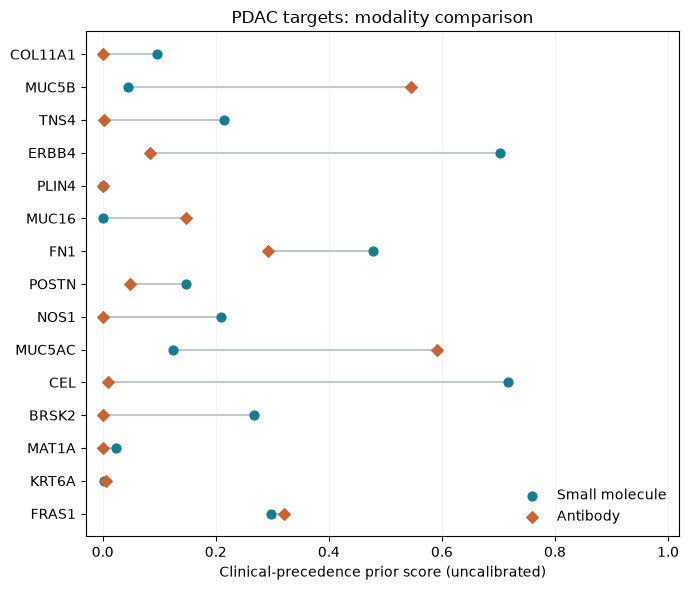

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
y = np.arange(len(targets))
ax.hlines(y, targets.p_sm, targets.p_ab, color="#BCC9CE", lw=1.5)
ax.scatter(targets.p_sm, y, s=40, color="#147D92", label="Small molecule", zorder=3)
ax.scatter(targets.p_ab, y, s=35, color="#C76535", marker="D", label="Antibody", zorder=3)
ax.set_yticks(y, targets.gene)
ax.invert_yaxis()
ax.set(xlabel="Clinical-precedence prior score (uncalibrated)",
       xlim=(-0.03, 1.02), title="PDAC targets: modality comparison")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="x", alpha=0.15)
fig.tight_layout()
fig.savefig(RESULTS / "modality_map.png", dpi=180)
plt.show()

## Step 5 · Nearest known drug targets

For each target, the three most similar training-panel proteins **with clinical precedence**, with cosine similarity. This is the evidence behind each prior.

In [8]:
clinical = train["any_clinical"].to_numpy(dtype=bool)
drugged = train.loc[clinical].reset_index(drop=True)
S = cosine_matrix(X_targets, X_train[clinical])
nearest, neighbor_rows = [], []
for i, gene in enumerate(targets.gene):
    idx = np.argsort(-S[i])[:3]
    nearest.append("; ".join(f"{drugged.iloc[j].gene} ({S[i,j]:.3f})" for j in idx))
    for j in idx:
        r = drugged.iloc[j]
        neighbor_rows.append({"gene": gene, "neighbor": r.gene, "cosine": float(S[i,j]),
                              "sm_clinical": r.sm_clinical, "ab_clinical": r.ab_clinical})
targets["nearest_drug_targets"] = nearest
pd.DataFrame(neighbor_rows).to_csv(RESULTS / "nearest_neighbors.csv", index=False)
display(targets[["gene", "nearest_drug_targets"]])

,gene,nearest_drug_targets
0,COL11A1,COL1A2 (0.951); COL3A1 (0.949); COL4A5 (0.887)
1,MUC5B,LAMB2 (0.941); ICAM3 (0.940); PMEL (0.940)
2,TNS4,TRAF3IP2 (0.959); IL4R (0.955); MAP3K13 (0.949)
3,ERBB4,FGFR1 (0.961); EPHA3 (0.959); EPHA5 (0.953)
4,PLIN4,CDK13 (0.771); CDK12 (0.761); BRD4 (0.757)
5,MUC16,PTHLH (0.891); IL4R (0.855); FGA (0.848)
6,FN1,NRP1 (0.933); LAMC2 (0.928); LAMA4 (0.927)
7,POSTN,LAMA4 (0.949); NRP1 (0.948); FGB (0.946)
8,NOS1,NOS2 (0.993); MAP3K5 (0.970); NCBP1 (0.970)
9,MUC5AC,MMP9 (0.928); SEMA4D (0.926); CACNA2D2 (0.921)


## Step 6 · Anchor variants (required for everyone)

Report score and within-protein percentile for **APOE R176C (rs7412, ε2)**, **APOE C130R (rs429358, ε4)**, **TREM2 R47H**, and **one p53 hotspot** of your choice. UniProt numbering includes APOE's 18-residue signal peptide (mature names: R158C and C112R).

In [9]:
anchors = pd.read_csv(DATA / "anchor_variants.tsv", sep="\t")
P53_CHOICE = "R175H"
wanted = {("APOE", "R176C"), ("APOE", "C130R"), ("TREM2", "R47H"), ("TP53", P53_CHOICE)}
my_anchors = anchors[[ (g, v) in wanted for g, v in zip(anchors.gene, anchors.variant) ]].copy()
assert len(my_anchors) == 4
# Cross-check supplied scores and percentiles against all substitutions in that protein.
for i, r in my_anchors.iterrows():
    all_scores = pd.read_csv(DATA / f"variant_scores_{r.gene}.tsv", sep="\t")
    score = all_scores.loc[all_scores.variant.eq(r.variant), "score"].iloc[0]
    pct = 100 * (all_scores.score <= score).mean()
    assert np.isclose(score, r.score) and abs(pct - r.percentile_in_protein) < 0.11
    sequence = proteome.loc[proteome.gene.eq(r.gene), "sequence"].iloc[0]
    assert sequence[int(r.variant[1:-1])-1] == r.variant[0]
    my_anchors.loc[i, "percentile_checked"] = pct
my_anchors.to_csv(RESULTS / "anchor_variants_selected.csv", index=False)
print("UniProt precursor numbering; APOE mature residue = precursor residue - 18.")
print("Low percentile = more negative relative to all single substitutions in the same protein.")
display(my_anchors.round(3))

UniProt precursor numbering; APOE mature residue = precursor residue - 18.
Low percentile = more negative relative to all single substitutions in the same protein.


,gene,variant,note,score,percentile_in_protein,percentile_checked
0,TP53,R175H,hotspot,-5.974,19.3,19.325
7,APOE,C130R,"rs429358, defines e4 (C112R mature)",7.208,100.0,100.000
8,APOE,R176C,"rs7412, defines e2 (R158C mature)",-8.559,11.8,11.821
9,TREM2,R47H,"rs75932628, AD risk variant",-5.156,47.7,47.712


## Step 7 · Re-rank and export

Combine your Module 2 evidence with the best-modality tractability prior. Choose the weight `w` (0 = tractability only, 1 = Module 2 only) and **justify it in your report**.

In [10]:
targets["week2_pct"] = targets["score"].rank(pct=True)
targets["tract"] = targets[["p_sm", "p_ab"]].max(axis=1)
targets["tract_pct"] = targets.tract.rank(pct=True)
targets["final"] = w * targets.week2_pct + (1-w) * targets.tract_pct
# Break any tied final score by Week 2 score, then gene, reproducibly.
targets = targets.sort_values(["final", "score", "gene"], ascending=[False, False, True]).reset_index(drop=True)
targets["rank"] = np.arange(1, len(targets)+1)
out = targets.rename(columns={"score": "week2_score"})[
    ["gene", "week2_score", "p_sm", "p_ab", "nearest_drug_targets", "final", "rank"]]
out_file = f"targets_{DISEASE}_w3.csv"
out.to_csv(out_file, index=False)
assert len(out) == 15 and out.gene.is_unique and out.notna().all().all()
print(f"Wrote {out_file}")
display(out.round(3))

Wrote targets_pdac_w3.csv


,gene,week2_score,p_sm,p_ab,nearest_drug_targets,final,rank
0,MUC5B,0.976,0.045,0.545,LAMB2 (0.941); ICAM3 (0.940); PMEL (0.940),0.893,1
1,ERBB4,0.973,0.702,0.083,FGFR1 (0.961); EPHA3 (0.959); EPHA5 (0.953),0.840,2
2,COL11A1,0.984,0.096,0.000,COL1A2 (0.951); COL3A1 (0.949); COL4A5 (0.887),0.780,3
3,TNS4,0.975,0.215,0.003,TRAF3IP2 (0.959); IL4R (0.955); MAP3K13 (0.949),0.767,4
4,FN1,0.971,0.478,0.292,NRP1 (0.933); LAMC2 (0.928); LAMA4 (0.927),0.640,5
5,MUC16,0.971,0.000,0.148,PTHLH (0.891); IL4R (0.855); FGA (0.848),0.587,6
6,MUC5AC,0.962,0.125,0.592,MMP9 (0.928); SEMA4D (0.926); CACNA2D2 (0.921),0.540,7
7,PLIN4,0.972,0.000,0.000,CDK13 (0.771); CDK12 (0.761); BRD4 (0.757),0.533,8
8,CEL,0.953,0.718,0.009,GPA33 (0.908); MMP9 (0.907); TNKS2 (0.906),0.533,9
9,POSTN,0.971,0.147,0.048,LAMA4 (0.949); NRP1 (0.948); FGB (0.946),0.473,10


In [11]:
moved = targets.assign(week2_rank=targets["score"].rank(ascending=False, method="first").astype(int))
moved["change"] = moved.week2_rank - moved["rank"]
moved.to_csv(RESULTS / "target_audit.csv", index=False)
print("Positive change = moved up; negative = moved down.")
display(moved[["gene", "week2_rank", "rank", "change", "p_sm", "p_ab", "truncated_main"]].round(3))
print("Spearman Week 2 vs tractability:", round(targets.score.corr(targets.tract, method="spearman"), 3))
print("Spearman Week 2 vs final:", round(targets.score.corr(targets.final, method="spearman"), 3))

Positive change = moved up; negative = moved down.


,gene,week2_rank,rank,change,p_sm,p_ab,truncated_main
0,MUC5B,2,1,1,0.045,0.545,True
1,ERBB4,4,2,2,0.702,0.083,False
2,COL11A1,1,3,-2,0.096,0.000,False
3,TNS4,3,4,-1,0.215,0.003,False
4,FN1,7,5,2,0.478,0.292,True
5,MUC16,6,6,0,0.000,0.148,True
6,MUC5AC,10,7,3,0.125,0.592,True
7,PLIN4,5,8,-3,0.000,0.000,False
8,CEL,11,9,2,0.718,0.009,False
9,POSTN,8,10,-2,0.147,0.048,False


Spearman Week 2 vs tractability: 0.039
Spearman Week 2 vs final: 0.901


## Short robustness checks
Weights 0.5/0.7/0.9 test how much the decision depends on the chosen mixture. The supplied ESM2 baseline is a sensitivity check, not a model selected for a preferred result. Its shorter sequence limit also differs from ESM-C. Neither model is tuned to the target list.

In [12]:
sensitivity = targets[["gene", "rank"]].copy()
for weight in [0.5, 0.7, 0.9]:
    s = targets.assign(mix=weight*targets.week2_pct + (1-weight)*targets.tract_pct)
    s = s.sort_values(["mix", "score", "gene"], ascending=[False, False, True])
    rank_map = dict(zip(s.gene, range(1, len(s)+1)))
    sensitivity[f"rank_w{weight}"] = sensitivity.gene.map(rank_map)
X_base = np.load(DATA / "panel_emb_baseline.npy").astype("float32")[keep]
P_base = np.load(DATA / "proteome_emb_baseline.npy").astype("float32")
base_target = P_base[targets.row]
base_sm = fit_prior(X_base, train.sm_clinical).predict_proba(base_target)[:,1]
base_ab = fit_prior(X_base, train.ab_clinical).predict_proba(base_target)[:,1]
sensitivity["p_sm_baseline"], sensitivity["p_ab_baseline"] = base_sm, base_ab
s = targets.assign(mix=w*targets.week2_pct + (1-w)*pd.Series(np.maximum(base_sm, base_ab)).rank(pct=True))
s = s.sort_values(["mix", "score", "gene"], ascending=[False, False, True])
sensitivity["rank_baseline"] = sensitivity.gene.map(dict(zip(s.gene, range(1,len(s)+1))))
sensitivity.to_csv(RESULTS / "sensitivity.csv", index=False)
display(sensitivity.round(3))
base_validation = evaluate(X_base, train.any_clinical, train.family_group)
base_validation.to_csv(RESULTS / "baseline_validation.csv")
print("ESM2 baseline, any-clinical label:")
display(base_validation)
# Record versions and the source pack fingerprint for reproducibility.
import sys, hashlib, sklearn
files = sorted(DATA.glob("*")) + [Path(TARGETS_FILE)]
run_info = {"python": sys.version, "numpy": np.__version__, "pandas": pd.__version__,
            "sklearn": sklearn.__version__, "seed": SEED, "weight": w,
            "removed_panel_genes": removed, "unmapped_genes": unmapped,
            "sha256": {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in files}}
(RESULTS / "run_info.json").write_text(json.dumps(run_info, indent=2))
print("All analysis steps completed.")

,gene,rank,rank_w0.5,rank_w0.7,rank_w0.9,p_sm_baseline,p_ab_baseline,rank_baseline
0,MUC5B,1,1,1,2,0.197,0.176,3
1,ERBB4,2,2,2,4,0.722,0.231,1
2,COL11A1,3,6,3,1,0.051,0.010,2
3,TNS4,4,3,4,3,0.018,0.003,5
4,FN1,5,4,5,7,0.097,0.444,6
5,MUC16,6,8,6,6,0.002,0.014,8
6,MUC5AC,7,7,7,10,0.230,0.255,12
7,PLIN4,8,12,8,5,0.414,0.014,4
8,CEL,9,5,9,11,0.821,0.002,7
9,POSTN,10,10,10,8,0.032,0.123,10


ESM2 baseline, any-clinical label:


,AUROC,Average precision
Random split,0.803,0.664
Family split,0.719,0.528


All analysis steps completed.


## My findings and Week 4 choices

- **Re-ranking:** MUC5B is first, ERBB4 second, COL11A1 third. MUC5AC gains three positions (10 → 7); PLIN4 loses three (5 → 8), the largest movements. ERBB4 remains near the top across weights and both embeddings. This is a short-list ranking, not a measure of treatment benefit.
- **Validation:** family-split any-clinical AUROC/AP is **0.740/0.559**, compared with random-split **0.845/0.726**. Family small-molecule metrics are **0.738/0.492**; antibody **0.892/0.364**. Antibody labels are rare (67/1,200), so AP matters alongside AUROC. Antibody AUROC did not fall; I report that observation rather than assume all metrics must decline.
- **Modality:** ERBB4 has p_sm=0.702 and p_ab=0.083. It is a cell-surface receptor with an intracellular kinase pocket; the low antibody score does not mean its extracellular region is inaccessible. A ligand-bound ERBB4 kinase structure is available as [PDB 3BBT](https://www.rcsb.org/structure/3BBT).
- **Variants:** APOE epsilon4 is +7.208 at the 100th percentile, whereas epsilon2 is -8.559 at the 11.8th percentile. Sequence compatibility is not clinical risk. TREM2 R47H is -5.156 (47.7th percentile); TP53 R175H is -5.974 (19.3rd percentile). See the report for numbering, interpretation and references.
- **Week 4:** I choose **ERBB4** (rank 2) as the stronger structural starting point and **BRSK2** (rank 12) as a lower-confidence, literature-supported hypothesis. Both main embeddings are untruncated. BRSK2 has a modest main p_sm=0.267, despite a plausible kinase pocket and published preclinical PDAC/inhibitor evidence. These choices do not alter the exported ranks.
- **Unresolved biology:** ERBB4 RNA decreases while protein increases; BRSK2 decreases in both bulk measurements. Check cell type, activity and dependence before proposing inhibition. MUC5B's first-place rank is not sufficient for pocket follow-up because its embedding is truncated.

**Sources for these biological interpretations:** [UniProt ERBB4](https://www.uniprot.org/uniprotkb/Q15303/entry); [Open Targets tractability](https://platform-docs.opentargets.org/target/tractability); [BRSK2 PDAC experiments](https://doi.org/10.18632/oncotarget.17965); [BRSK2 inhibitor study](https://doi.org/10.1038/s41598-020-72869-9); [APOE genotype association](https://pubmed.ncbi.nlm.nih.gov/9343467/); [TREM2 association](https://doi.org/10.1056/NEJMoa1211851). Full references and limitations are in the PDF report.
